In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn import metrics



In [2]:
df = pd.read_csv("robot_zone_data.csv")

X, y = df[["x_m", "y_m"]], df["zone"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)



In [4]:
X_test.head()

,x_m,y_m
132,-0.11,-0.13
148,2.12,-0.03
93,-1.42,-2.34
180,3.71,-0.79
15,0.48,1.56


In [6]:
y_test.head()

132    danger
148      safe
93       safe
180      safe
15     danger
Name: zone, dtype: str

In [7]:
for k in ["linear", "rbf"]:
    model = make_pipeline(StandardScaler(), SVC(kernel=k))
    model.fit(X_train, y_train)
    print(k, "accuracy:", round(model.score(X_test, y_test), 2))



linear accuracy: 0.48
rbf accuracy: 0.91


In [8]:
y_pred = model.predict(X_test)  # The last model is rbf



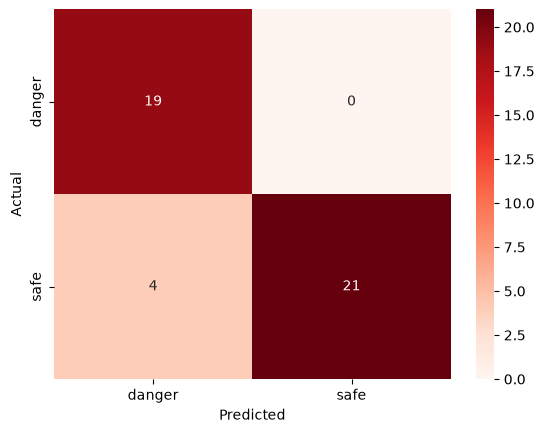

In [11]:
labels = ["danger", "safe"]

cm = metrics.confusion_matrix(y_test, y_pred, labels=labels)

sns.heatmap(
    cm,
    annot=True,
    cmap="Reds",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()